In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np
import pandas as pd
from IPython.display import Image, display
from clima_ecuador import config
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
R = json.loads(config.RESULTADOS.read_text(encoding="utf-8"))
def figura(nombre, ancho=950):
    display(Image(filename=str(config.FIGURAS / nombre), width=ancho))
def reporte(nombre):
    return pd.read_csv(config.REPORTES / nombre)

# 05 · El Niño y el clima del Ecuador

**Pregunta:** ¿cuánto del clima del Ecuador explica El Niño, con cuánta anticipación, y qué índice sirve mejor?

* **ONI** (NOAA): anomalía de 3 meses de la temperatura del mar en Niño 3.4 (Pacífico central). El índice oficial.
* **Niño 1+2**: anomalía del mar frente a la costa del Ecuador y el Perú (0–10° S, 90–80° O).
* Correlaciones de anomalías mensuales con rezagos de 0 a 6 meses. Significancia con **tamaño de muestra efectivo**
  (Bretherton et al. 1999): 540 meses muy autocorrelacionados equivalen a ~35–100 datos independientes.

In [2]:
from clima_ecuador import enso
oni = pd.read_csv(config.ONI, parse_dates=["fecha"])
oni["fase"].value_counts()

fase
Neutral    271
El Niño    144
La Niña    137
Name: count, dtype: int64

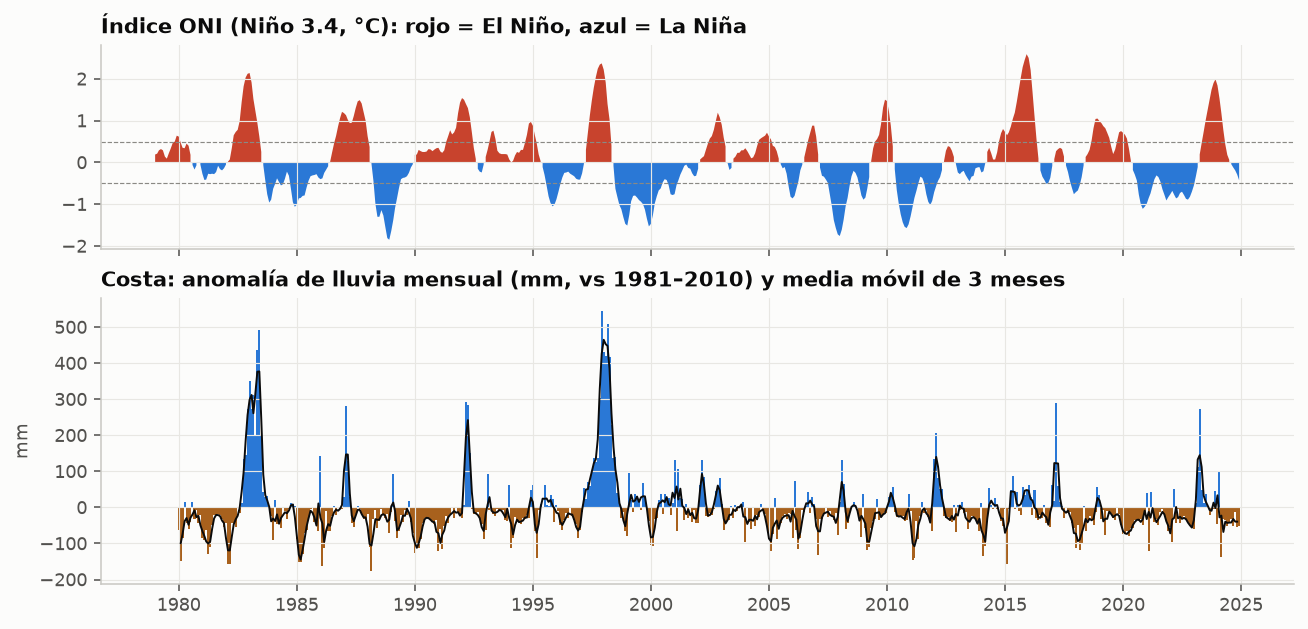

In [3]:
figura("12_enso_costa.png")

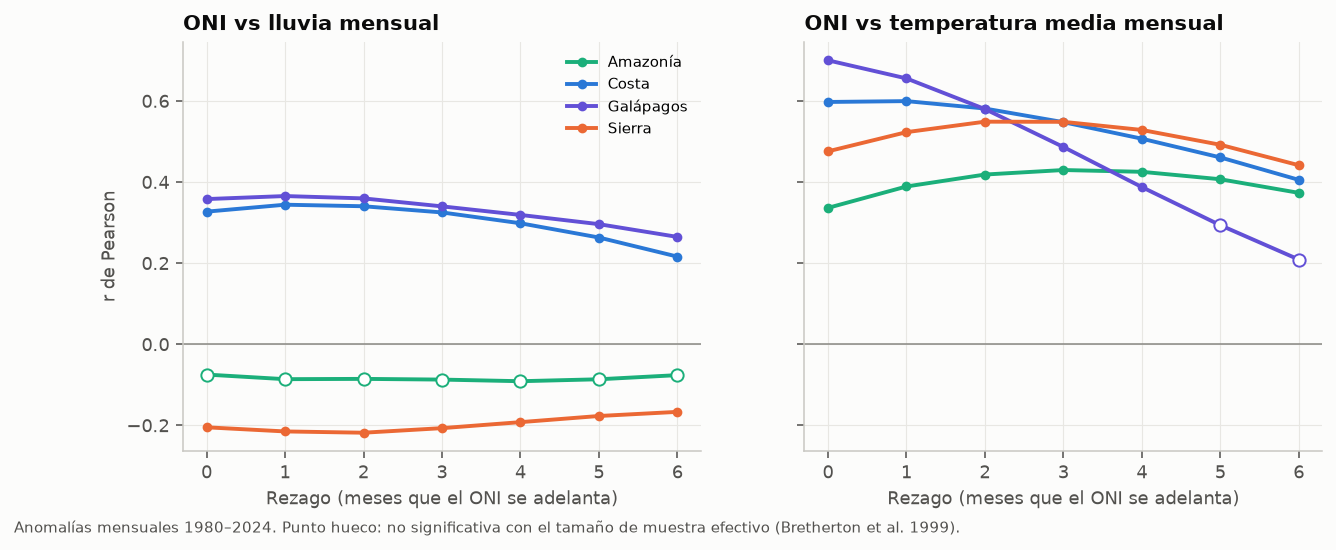

,region,variable,rezago,r,n_efectivo,p,p_ingenuo
0,Amazonía,precip_pct,4,-0.091,278.344,0.131,0.035
1,Amazonía,tmax,4,0.321,102.091,0.001,0.000
2,Amazonía,tmed,3,0.430,75.257,0.000,0.000
3,Costa,precip_pct,1,0.344,91.568,0.001,0.000
4,Costa,tmax,0,0.524,42.628,0.000,0.000
5,Costa,tmed,1,0.600,34.975,0.000,0.000
6,Galápagos,precip_pct,1,0.366,80.712,0.001,0.000
7,Galápagos,tmax,0,0.693,40.493,0.000,0.000
8,Galápagos,tmed,0,0.701,39.321,0.000,0.000
9,Sierra,precip_pct,2,-0.218,379.692,0.000,0.000


In [4]:
figura("11_enso_rezagos.png")
pd.DataFrame(R["enso_regiones"])[["region", "variable", "rezago", "r", "n_efectivo", "p", "p_ingenuo"]]

* La **temperatura** responde a El Niño en todo el país: r = 0,70 en Galápagos y 0,60 en la Costa (sin rezago);
  en la Sierra y la Amazonía la respuesta llega **2–3 meses después** (r = 0,55 y 0,43).
* La **lluvia** sube con El Niño en la Costa y Galápagos (r ≈ 0,35) y **baja en la Sierra** (r = −0,22):
  El Niño seca los Andes ecuatorianos. En la Amazonía no hay relación significativa.
* El `p_ingenuo` (sin tamaño efectivo) es siempre mucho menor: en la Amazonía la lluvia saldría "significativa"
  (p = 0,035) y con el tamaño efectivo no lo es (p = 0,13).

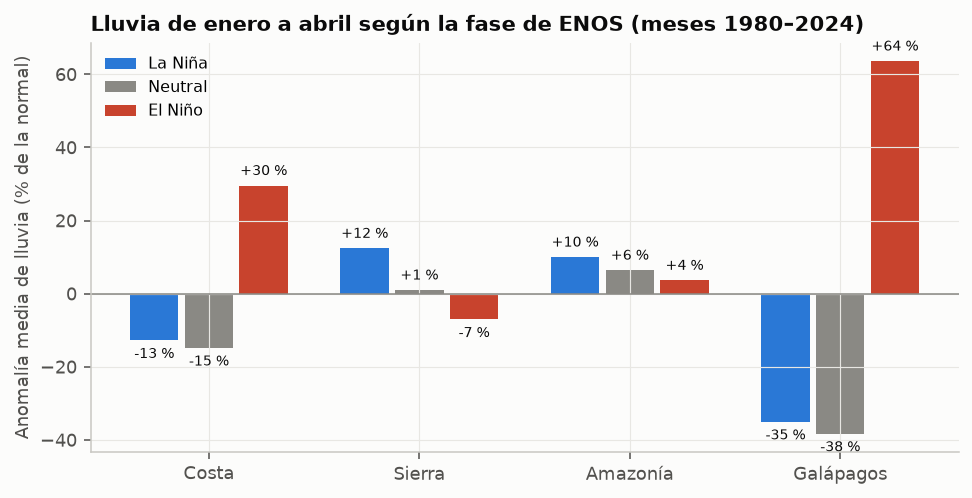

,region,fase,media,mediana,meses
0,Amazonía,El Niño,3.600,1.700,49
1,Amazonía,La Niña,10.000,6.200,51
2,Amazonía,Neutral,6.400,7.100,80
3,Costa,El Niño,29.600,1.400,49
4,Costa,La Niña,-12.700,-20.800,51
5,Costa,Neutral,-14.800,-25.600,80
6,Galápagos,El Niño,63.600,-21.000,49
7,Galápagos,La Niña,-35.000,-57.000,51
8,Galápagos,Neutral,-38.200,-63.200,80
9,Sierra,El Niño,-7.000,-4.700,49


In [5]:
figura("13_enso_compuestos.png", 760)
reporte("enso_compuestos_ene_abr.csv").round(1)

La media y la mediana de la Costa con El Niño son muy distintas (+30 % y +1 %): el efecto lo ponen **pocos
eventos enormes**. Por eso conviene mirar los episodios uno por uno.

In [6]:
reporte("enso_episodios_fuertes.csv").query("region in ['Costa', 'Galápagos']").round(2)

,inicio,fin,oni_max,region,lluvia_pct_normal,anomalia_tmed
1,1982-10,1983-03,2.140,Costa,349.340,1.430
2,1982-10,1983-03,2.140,Galápagos,837.920,1.860
5,1992-01,1992-02,1.540,Costa,174.980,0.690
6,1992-01,1992-02,1.540,Galápagos,286.320,0.660
9,1997-08,1998-02,2.370,Costa,414.090,1.440
10,1997-08,1998-02,2.370,Galápagos,684.740,2.780
13,2009-12,2009-12,1.500,Costa,95.670,1.000
14,2009-12,2009-12,1.500,Galápagos,79.890,0.550
17,2015-08,2016-03,2.590,Costa,100.100,1.670
18,2015-08,2016-03,2.590,Galápagos,128.360,1.530


**El hallazgo central del notebook:** 1982-83 y 1997-98 multiplicaron por 3,5 y 4,1 la lluvia de la Costa,
pero **2015-16, con el ONI más alto de la serie (2,59), dejó lluvia normal** y 2023-24 dejó 83 % de la normal.
El ONI mide el Pacífico central; lo que inunda la Costa es que se caliente **el mar frente a ella**.

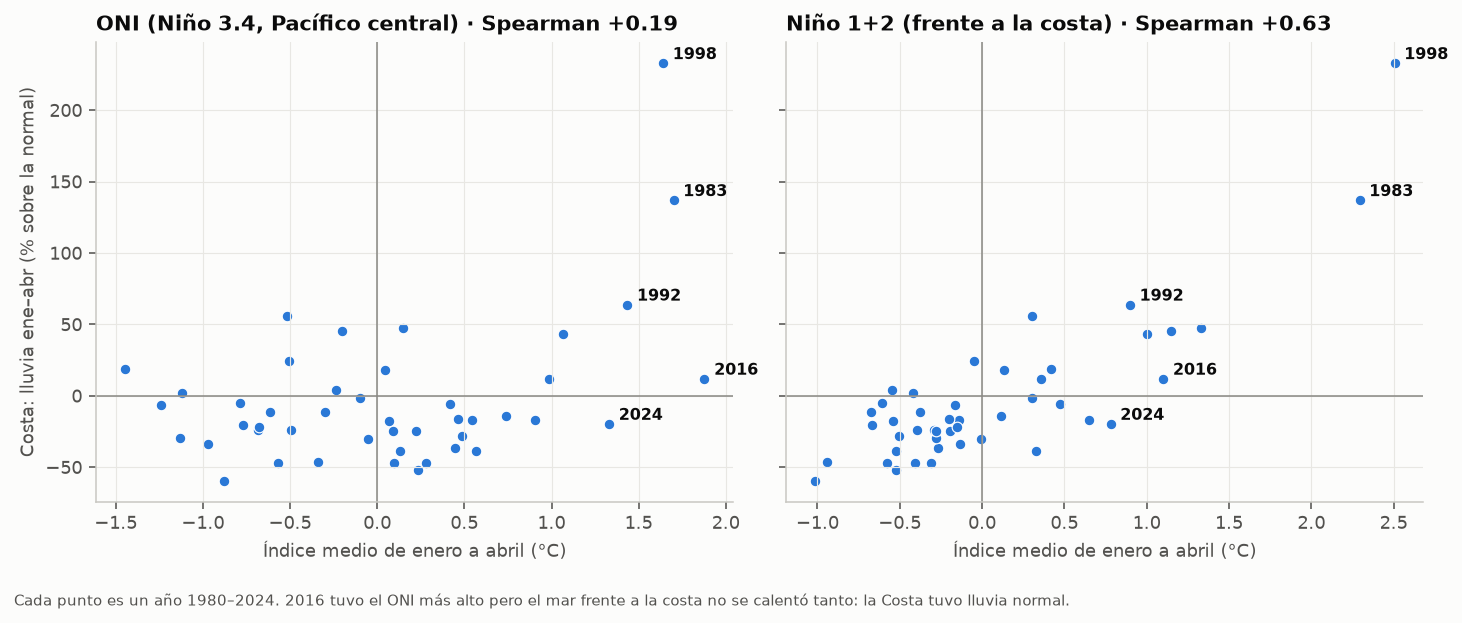

,region,indice,n_anios,r_pearson,r_spearman,p_spearman
0,Costa,oni,45,0.429,0.191,0.208
1,Costa,nino12,45,0.839,0.634,0.000
2,Sierra,oni,45,-0.329,-0.411,0.005
3,Sierra,nino12,45,0.004,-0.077,0.615
4,Amazonía,oni,45,-0.105,-0.151,0.323
5,Amazonía,nino12,45,0.134,0.064,0.678
6,Galápagos,oni,45,0.473,0.163,0.285
7,Galápagos,nino12,45,0.760,0.504,0.000


In [7]:
figura("18_enso_oni_vs_nino12.png")
reporte("enso_oni_vs_nino12.csv").round(3)

In [8]:
t = reporte("enso_temporada_ene_abr.csv")
t[t["anio"].isin([1983, 1987, 1992, 1998, 2016, 2024])].round(2)

,anio,Amazonía,Costa,Galápagos,Sierra,oni,nino12
3,1983,-4.110,137.140,326.970,5.260,1.700,2.290
7,1987,17.910,43.610,202.680,-4.810,1.070,1.000
12,1992,2.870,63.960,160.830,4.470,1.440,0.900
18,1998,-7.780,233.070,403.600,-12.440,1.640,2.500
36,2016,8.920,12.080,-72.110,2.980,1.880,1.100
44,2024,-7.600,-19.510,3.030,-4.960,1.330,0.780


* Lluvia de enero–abril en la Costa: **r = 0,84 con Niño 1+2** frente a 0,43 con el ONI (Spearman 0,63 vs 0,19,
  y el del ONI no es significativo). Galápagos igual: 0,76 frente a 0,47.
* En la **Sierra** es al revés: responde al ONI (Spearman −0,41) y no a Niño 1+2. El Pacífico central actúa sobre
  los Andes a través de la circulación atmosférica, no del mar costero.
* **Para alertas tempranas en la Costa conviene vigilar Niño 1+2, no solo el ONI** que se cita en las noticias.